# JalanKu — Notebook 04: Aplikasi

## Tujuan notebook ini
Notebook ini menjelaskan lapisan aplikasi JalanKu: bagaimana halaman web di HP dan server FastAPI di laptop bekerja sama, bagaimana satu frame kamera diubah menjadi satu peringatan
(aturan bahaya, zona, jarak, stabilisasi, dan aturan suara), seberapa cepat server berjalan, seberapa dekat hasil server dengan evaluasi offline, bagaimana aturan peringatan dipilih lewat
**ablasi tanpa pelatihan**, apa yang terjadi saat ambang kendaraan dinaikkan dari 0,10 ke 0,25, dan apa yang diketahui tentang kamera yang menempel ke tembok. Notebook ini **hanya membaca**
kode dan hasil yang sudah tersimpan (`src/`, `data/`, `docs/`); server tidak dijalankan, tidak ada pelatihan, evaluasi, atau inferensi model, dan tidak ada berkas `.pt` yang dimuat.
Semua angka dihitung dari berkas oleh sel kode, bukan diketik manual, **kecuali** satu bagian yang diberi label jelas sebagai catatan uji pemakaian yang dicatat manual oleh penguji (bagian 9).
Setiap bagian ditutup dengan "Bacaan" yang menyebutkan juga kelemahannya.

## 0. Persiapan
Sel di bawah menentukan akar repo, memeriksa berkas sumber, dan menyiapkan fungsi pembantu. Satu-satunya kode proyek yang diimpor adalah `src/server/logika.py` (mesin aturan peringatan; hanya memakai
pustaka standar, tidak memuat torch atau model), supaya tabel bahaya di bawah dihitung dari kode aslinya. Folder `data/`, `runs/`, dan `models/` tidak masuk Git.

In [1]:
import csv, json, re, io, html, collections, pickle, sys, ast
from pathlib import Path

import numpy as np
import yaml
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from IPython.display import display, HTML, Markdown

# ROOT = akar repo (induk folder notebooks/); dicari ke atas dari folder kerja
ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "docs").is_dir():
    ROOT = ROOT.parent
DATA = ROOT / "data"
SRV = ROOT / "src" / "server"
WEB = ROOT / "src" / "web"

def rel(p):
    try:
        return Path(p).resolve().relative_to(ROOT).as_posix()
    except ValueError:
        return Path(p).name

def baca(p):
    return Path(p).read_text(encoding="utf-8-sig", errors="replace")

def baca_json(p):
    return json.loads(baca(p))

def baca_csv(p):
    with open(p, newline="", encoding="utf-8-sig") as f:
        return list(csv.DictReader(f))

WAJIB = [
    "src/server/config.yaml", "src/server/logika.py", "src/server/deteksi.py", "src/server/ensemble.py", "src/server/main.py",
    "src/web/app.js", "src/web/suara.js", "src/web/server.js", "docs/status.md",
    "data/test-final/ens_kecepatan_protokol.json", "data/test-final/LOG.md",
    "data/server-v2/kecepatan.json", "data/server-v2/uji_http.txt", "data/server-v2/ekuivalensi_fp32.json", "data/server-v2/ekuivalensi_half.json",
    "data/server-v2/diag_ekuivalensi.txt", "data/server-v2/uji_logika.py", "data/server-v2/LOG.md",
    "data/aturan-peringatan/hasil_ablasi.md", "data/aturan-peringatan/ablasi_frame.csv", "data/aturan-peringatan/cache_deteksi.pkl", "data/aturan-peringatan/ablasi.py",
    "data/diagnosa-mepet/d2_ringkasan.csv", "data/diagnosa-mepet/d2_log.txt", "data/diagnosa-mepet/hasil.csv",
]
hilang = [w for w in WAJIB if not (ROOT / w).exists()]
if hilang:
    print("BERKAS TIDAK DITEMUKAN (data/, runs/, models/ tidak ikut Git):")
    for w in hilang:
        print("  -", w)
    print("Notebook ini hanya bisa dijalankan ulang di laptop yang memiliki folder tersebut.")
    print("Di tempat lain, lihat saja keluaran yang sudah tersimpan di notebook.")
else:
    print("Semua", len(WAJIB), "berkas sumber ditemukan. ROOT = (akar repo)")

# mesin logika asli (tanpa menulis bytecode ke src/, tanpa torch)
sys.dont_write_bytecode = True
sys.path.insert(0, str(SRV))
import logika
print("torch dimuat?", "torch" in sys.modules, "| ultralytics dimuat?", "ultralytics" in sys.modules, "| cv2 dimuat?", "cv2" in sys.modules)
assert "torch" not in sys.modules and "ultralytics" not in sys.modules

def tabel(kepala, baris, rata_kanan=None):
    rata_kanan = set(rata_kanan or [])
    h = "<table style='border-collapse:collapse;font-size:90%'>"
    h += "<tr>" + "".join(f"<th style='border:1px solid #888;padding:3px 8px;background:#eee;color:#000'>{html.escape(str(c))}</th>" for c in kepala) + "</tr>"
    for r in baris:
        h += "<tr>"
        for i, c in enumerate(r):
            al = "right" if i in rata_kanan else "left"
            h += f"<td style='border:1px solid #888;padding:3px 8px;text-align:{al}'>{html.escape(str(c))}</td>"
        h += "</tr>"
    display(HTML(h + "</table>"))

def tabel_md(teks, awal):
    # tabel markdown pertama setelah baris yang memuat `awal` (baris kepala tabel ikut sebagai baris pertama)
    baris, ada = [], False
    for ln in teks.splitlines():
        if not ada:
            ada = awal in ln
            continue
        s = ln.strip()
        if s.startswith("|"):
            sel = [c.strip() for c in s.strip("|").split("|")]
            if all(set(c) <= set("-: ") for c in sel):
                continue
            baris.append(sel)
        elif baris:
            break
    return baris

def kutipan(teks):
    display(HTML("<blockquote style='border-left:4px solid #888;margin:6px 0;padding:4px 12px;font-size:90%'>" + html.escape(teks) + "</blockquote>"))

def f1(x):
    return f"{x:.1f}"

plt.rcParams.update({"figure.dpi": 100, "font.size": 9, "axes.grid": True, "grid.alpha": 0.3})
LOG_UJI = baca(DATA / "server-v2/LOG.md")
def entri(tag, teks=LOG_UJI):
    for ln in teks.splitlines():
        if ln.startswith(f"- [{tag}]"):
            return ln
    raise KeyError(tag)
CFG = yaml.safe_load(baca(SRV / "config.yaml"))
JS_APP, JS_SUARA, JS_SERVER = baca(WEB / "app.js"), baca(WEB / "suara.js"), baca(WEB / "server.js")
print("Siap.")

Semua 25 berkas sumber ditemukan. ROOT = (akar repo)
torch dimuat? False | ultralytics dimuat? False | cv2 dimuat? False
Siap.


## 1. Arsitektur
Aplikasi berupa **halaman web** (`src/web/`, dibuka di Chrome HP) dan **server FastAPI** (`src/server/`) yang berjalan di laptop. HP mengirim frame kamera lewat jaringan lokal (hotspot HP, HTTPS dengan sertifikat buatan sendiri; dari `docs/status.md`),
server menjalankan model kotak (ensemble C2) dan model segmentasi, lalu membalas **satu peringatan per frame**. Suara (TTS bahasa Indonesia), getar, dan gambar kotak dilakukan di HP. Nilai pada diagram dibaca dari `config.yaml`, `app.js`, dan `suara.js`.

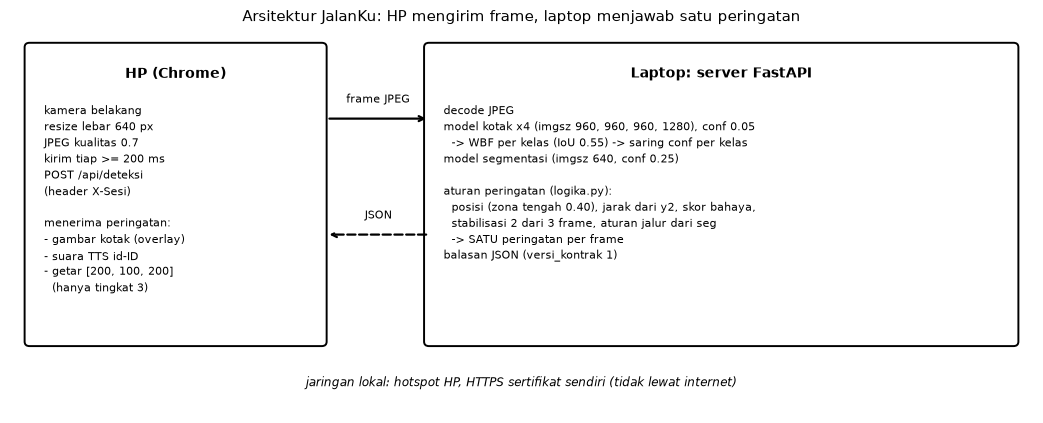

Batas waktu tunggu HP: 3000 ms; jeda minimum antar kiriman: 200 ms (maksimum 5 frame/detik dari sisi HP).


In [2]:
def js(pola, teks=JS_APP, tipe=float):
    return tipe(re.search(pola, teks).group(1))

LEBAR = js(r"LEBAR_KIRIM\s*=\s*(\d+)", tipe=int)
MUTU = js(r"KUALITAS_JPEG\s*=\s*([\d.]+)")
JEDA_KIRIM = js(r"jedaKirimMs\s*=\s*(\d+)", tipe=int)
WAKTU_HABIS = js(r"WAKTU_HABIS_MS\s*=\s*(\d+)", JS_SERVER, int)
JEDA_ULANG = js(r"jedaUlangMs:\s*(\d+)", JS_SUARA, int)
JEDA_RINGAN = js(r"jedaKelasRinganMs:\s*(\d+)", JS_SUARA, int)
GETAR = re.search(r"navigator\.vibrate\((\[[^\]]*\])\)", JS_SUARA).group(1)
anggota = CFG["ensemble_kotak"]
sz = ", ".join(str(a["imgsz"]) for a in anggota)

fig, ax = plt.subplots(figsize=(10.5, 4.3))
ax.set_xlim(0, 10.5); ax.set_ylim(0, 4.3); ax.axis("off"); ax.grid(False)
def kotak(x, y, w, h, judul, isi, hatch=None):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.05", fc="white", ec="black", lw=1.4, hatch=hatch))
    ax.text(x + w / 2, y + h - 0.22, judul, ha="center", va="top", fontsize=10, fontweight="bold")
    ax.text(x + 0.15, y + h - 0.62, isi, ha="left", va="top", fontsize=8, linespacing=1.45)
kotak(0.2, 0.8, 3.0, 3.3, "HP (Chrome)",
      f"kamera belakang\nresize lebar {LEBAR} px\nJPEG kualitas {MUTU}\nkirim tiap >= {JEDA_KIRIM} ms\nPOST /api/deteksi\n(header X-Sesi)\n\nmenerima peringatan:\n- gambar kotak (overlay)\n- suara TTS id-ID\n- getar {GETAR}\n  (hanya tingkat 3)")
kotak(4.3, 0.8, 6.0, 3.3, "Laptop: server FastAPI",
      f"decode JPEG\nmodel kotak x{len(anggota)} (imgsz {sz}), conf {CFG['conf_prediksi_kotak']}\n  -> WBF per kelas (IoU {CFG['wbf_iou']}) -> saring conf per kelas\nmodel segmentasi (imgsz {CFG['imgsz_seg']}, conf {CFG['conf_seg']})\n\naturan peringatan (logika.py):\n  posisi (zona tengah {CFG['zona_tengah']:.2f}), jarak dari y2, skor bahaya,\n  stabilisasi {CFG['stabil']['minimal']} dari {CFG['stabil']['jendela']} frame, aturan jalur dari seg\n  -> SATU peringatan per frame\nbalasan JSON (versi_kontrak 1)")
ax.annotate("", xy=(4.3, 3.3), xytext=(3.25, 3.3), arrowprops=dict(arrowstyle="->", lw=1.6))
ax.text(3.78, 3.48, "frame JPEG", ha="center", fontsize=8)
ax.annotate("", xy=(3.25, 2.0), xytext=(4.3, 2.0), arrowprops=dict(arrowstyle="->", lw=1.6, ls="--"))
ax.text(3.78, 2.18, "JSON", ha="center", fontsize=8)
ax.text(5.25, 0.3, "jaringan lokal: hotspot HP, HTTPS sertifikat sendiri (tidak lewat internet)", ha="center", fontsize=8.5, style="italic")
ax.set_title("Arsitektur JalanKu: HP mengirim frame, laptop menjawab satu peringatan", fontsize=10.5)
plt.tight_layout(); plt.show()
print(f"Batas waktu tunggu HP: {WAKTU_HABIS} ms; jeda minimum antar kiriman: {JEDA_KIRIM} ms (maksimum {1000 / JEDA_KIRIM:.0f} frame/detik dari sisi HP).")

In [3]:
display(Markdown(
    f"**Bacaan.** Seluruh pekerjaan model ada di laptop; HP hanya mengambil gambar, menampilkan, dan berbicara. Karena server memegang {len(anggota)} model kotak ditambah 1 model segmentasi, kecepatan ditentukan oleh GPU laptop (bagian 3). "
    f"HP menunggu paling lama {WAKTU_HABIS / 1000:.0f} detik per permintaan sebelum menyatakan server bermasalah, dan mengirim paling cepat {1000 / JEDA_KIRIM:.0f} frame per detik. "
    "Kelemahan: aplikasi hanya jalan selama laptop dan HP berada di satu jaringan lokal yang sama (jangkauan hotspot terbatas), dan frame kamera dikirim sebagai JPEG tanpa enkripsi di luar HTTPS lokal; tidak ada fallback di HP bila server mati."))

**Bacaan.** Seluruh pekerjaan model ada di laptop; HP hanya mengambil gambar, menampilkan, dan berbicara. Karena server memegang 4 model kotak ditambah 1 model segmentasi, kecepatan ditentukan oleh GPU laptop (bagian 3). HP menunggu paling lama 3 detik per permintaan sebelum menyatakan server bermasalah, dan mengirim paling cepat 5 frame per detik. Kelemahan: aplikasi hanya jalan selama laptop dan HP berada di satu jaringan lokal yang sama (jangkauan hotspot terbatas), dan frame kamera dikirim sebagai JPEG tanpa enkripsi di luar HTTPS lokal; tidak ada fallback di HP bila server mati.

## 2. Logika peringatan
Server mengubah daftar objek kotak dan mask segmentasi menjadi **satu** pesan per frame. Parameter dibaca dari `config.yaml` (nilai aktual yang terkunci) dan kode `logika.py`;
tabel tingkat bahaya dihitung dengan memanggil `MesinLogika.hitung_bahaya` pada konfigurasi itu.

In [4]:
L = logika.MesinLogika(CFG)
zt = CFG["zona_tengah"]; sisi = (1 - zt) / 2
bj = CFG["jarak_y2"]
print("Zona horizontal (titik tengah kotak):")
tabel(["Zona", "Lebar (fraksi lebar gambar)", "Faktor posisi"], [
    ["kiri", f"{sisi:.2f}", CFG["faktor_posisi"]["kiri"]], ["tengah", f"{zt:.2f}", CFG["faktor_posisi"]["tengah"]], ["kanan", f"{sisi:.2f}", CFG["faktor_posisi"]["kanan"]]], rata_kanan=[1, 2])
print("Jarak dari tepi bawah kotak (y2, fraksi tinggi gambar):")
tabel(["Kategori", "Syarat y2", "Faktor jarak"], [
    ["dekat", f">= {bj['dekat']}", CFG["faktor_jarak"]["dekat"]], ["sedang", f">= {bj['sedang']}", CFG["faktor_jarak"]["sedang"]], ["jauh", f"< {bj['sedang']}", CFG["faktor_jarak"]["jauh"]]], rata_kanan=[2])
amb = {int(k): v for k, v in CFG["ambang_tingkat"].items()}
print(f"Skor bahaya = bobot kelas x faktor posisi x faktor jarak. Tingkat 3 bila skor >= {amb[3]}, tingkat 2 bila >= {amb[2]}, selain itu tingkat 1.")
print("Peringatan aktif hanya jika objek di zona tengah ATAU berjarak dekat. Tingkat bahaya (t1/t2/t3; '-' = tidak jadi peringatan):")
kel = ["tengah", "samping"]
kolom = [("tengah", "dekat"), ("tengah", "sedang"), ("tengah", "jauh"), ("kiri", "dekat"), ("kiri", "sedang"), ("kiri", "jauh")]
baris = []
for k, bobot in sorted(CFG["bobot_kelas"].items(), key=lambda t: (-t[1], t[0])):
    r = [k, bobot]
    for pos, jar in kolom:
        h = L.hitung_bahaya(k, pos, jar)
        r.append(f"t{h['tingkat']}" if h["peringatan_aktif"] else "-")
    baris.append(r)
tabel(["Kelas", "Bobot", "tengah, dekat", "tengah, sedang", "tengah, jauh", "samping, dekat", "samping, sedang", "samping, jauh"], baris, rata_kanan=[1])
print("Contoh pesan suara:", ", ".join(repr(L.buat_pesan(k, p, j)) for k, p, j in (("tanaman_pot", "kanan", "dekat"), ("pilar", "tengah", "sedang"), ("tangga", "tengah", "dekat"))))

Zona horizontal (titik tengah kotak):


Zona,Lebar (fraksi lebar gambar),Faktor posisi
kiri,0.30,0.7
tengah,0.40,1.0
kanan,0.30,0.7


Jarak dari tepi bawah kotak (y2, fraksi tinggi gambar):


Kategori,Syarat y2,Faktor jarak
dekat,>= 0.85,1.0
sedang,>= 0.65,0.7
jauh,< 0.65,0.4


Skor bahaya = bobot kelas x faktor posisi x faktor jarak. Tingkat 3 bila skor >= 2.0, tingkat 2 bila >= 1.2, selain itu tingkat 1.
Peringatan aktif hanya jika objek di zona tengah ATAU berjarak dekat. Tingkat bahaya (t1/t2/t3; '-' = tidak jadi peringatan):


Kelas,Bobot,"tengah, dekat","tengah, sedang","tengah, jauh","samping, dekat","samping, sedang","samping, jauh"
kendaraan,3,t3,t3,t2,t3,-,-
tangga,3,t3,t3,t2,t3,-,-
tepian,3,t3,t3,t2,t3,-,-
orang,2,t3,t2,t1,t2,-,-
pilar,2,t3,t2,t1,t2,-,-
pohon,2,t3,t2,t1,t2,-,-
kursi,1,t1,t1,t1,t1,-,-
tanaman_pot,1,t1,t1,t1,t1,-,-


Contoh pesan suara: 'Tanaman pot di kanan, dekat', 'Pilar di depan, sedang', 'Tangga di depan, dekat'


In [5]:
ssrc = baca(SRV / "logika.py")
iou_stab = re.search(r">=\s*(0\.\d+)\s*\n\s*for sebelumnya", ssrc.replace("\r", "")) or re.search(r"hitung_iou\([^)]*\)\s*>=\s*(0\.\d+)", ssrc, re.S)
iou_stab = float(iou_stab.group(1)) if iou_stab else None
st = CFG["stabil"]
print("Stabilisasi, aturan dari seg, dan aturan suara:")
tabel(["Aturan", "Nilai (dibaca dari config.yaml / kode)", "Arti"], [
    ["stabilisasi objek kotak", f"{st['minimal']} dari {st['jendela']} frame (IoU >= {iou_stab}, kelas sama, per X-Sesi)", "objek baru jadi peringatan bila muncul di minimal N dari N frame terakhir"],
    ["'Tangga di depan' (seg)", f">= {CFG['seg_tangga_min'] * 100:.0f}% ROI bawah-tengah; harus jadi kandidat di {CFG['seg_tangga_stabil_minimal']} dari {st['jendela']} frame", "tingkat 3; stabilisasi lebih ketat (aturan C)"],
    ["'Area kendaraan, hati-hati' (seg)", f"jalan_kendaraan >= {CFG['seg_kendaraan_min'] * 100:.0f}% ROI; {st['minimal']} dari {st['jendela']} frame", "tingkat 2"],
    ["'Jalur terhalang' (seg)", f"jalur_jalan < {CFG['jalur_ambang_terhalang'] * 100:.0f}% ROI; {st['minimal']} dari {st['jendela']} frame", "tingkat 2; ROI = sepertiga bawah, selebar zona tengah"],
    ["'Hati-hati, jalur tidak terlihat'", f"seg tidak mengeluarkan mask {CFG['seg_kosong_minimal']} frame BERURUTAN", "tingkat 2; kamera menempel tembok atau gelap"],
    ["objek 'jauh' butuh seg (aturan B)", f"jauh_butuh_seg = {CFG['jauh_butuh_seg']}", "objek kotak 'jauh' tidak jadi peringatan bila seg kosong di frame itu"],
    ["satu peringatan per frame", "tingkat tertinggi; seri -> objek kotak", "peringatan seg menang hanya bila tingkatnya lebih tinggi"],
    ["suara: ulang pesan sama", f"jeda {JEDA_ULANG / 1000:.0f} dtk", "pesan yang sama tidak diucapkan lagi dalam jeda ini"],
    ["suara: benda ringan (tingkat 1)", f"kelas sama ditahan {JEDA_RINGAN / 1000:.0f} dtk (aturan A)", "walau teksnya berbeda (kanan/depan, dekat/sedang)"],
    ["suara: tingkat 3", f"memotong suara yang sedang bicara; getar {GETAR}", "getar tetap jalan walau Bisu"],
    ["suara: tingkat 1 dan 2", "tidak memotong dan tidak menumpuk antrean", "dilewati bila TTS masih berbicara"],
])
# kasus uji logika (hanya menghitung)
usrc = baca(DATA / "server-v2/uji_logika.py")
n_lama = int(re.search(r"(\d+) kasus lama", usrc).group(1))
n_baru = len(re.findall(r"^def k\d+\(", usrc, flags=re.M))
print(f"Uji logika sintetis (data/server-v2/uji_logika.py): {n_lama} kasus lama + {n_baru} kasus baru = {n_lama + n_baru} kasus.")

Stabilisasi, aturan dari seg, dan aturan suara:


Aturan,Nilai (dibaca dari config.yaml / kode),Arti
stabilisasi objek kotak,"2 dari 3 frame (IoU >= 0.3, kelas sama, per X-Sesi)",objek baru jadi peringatan bila muncul di minimal N dari N frame terakhir
'Tangga di depan' (seg),>= 5% ROI bawah-tengah; harus jadi kandidat di 3 dari 3 frame,tingkat 3; stabilisasi lebih ketat (aturan C)
"'Area kendaraan, hati-hati' (seg)",jalan_kendaraan >= 50% ROI; 2 dari 3 frame,tingkat 2
'Jalur terhalang' (seg),jalur_jalan < 20% ROI; 2 dari 3 frame,"tingkat 2; ROI = sepertiga bawah, selebar zona tengah"
"'Hati-hati, jalur tidak terlihat'",seg tidak mengeluarkan mask 3 frame BERURUTAN,tingkat 2; kamera menempel tembok atau gelap
objek 'jauh' butuh seg (aturan B),jauh_butuh_seg = True,objek kotak 'jauh' tidak jadi peringatan bila seg kosong di frame itu
satu peringatan per frame,tingkat tertinggi; seri -> objek kotak,peringatan seg menang hanya bila tingkatnya lebih tinggi
suara: ulang pesan sama,jeda 4 dtk,pesan yang sama tidak diucapkan lagi dalam jeda ini
suara: benda ringan (tingkat 1),kelas sama ditahan 8 dtk (aturan A),"walau teksnya berbeda (kanan/depan, dekat/sedang)"
suara: tingkat 3,"memotong suara yang sedang bicara; getar [200, 100, 200]",getar tetap jalan walau Bisu


Uji logika sintetis (data/server-v2/uji_logika.py): 11 kasus lama + 20 kasus baru = 31 kasus.


In [6]:
display(Markdown(
    f"**Bacaan.** Kelas berbobot 3 (tangga, tepian, kendaraan) langsung tingkat 3 bila di tengah dan dekat; kelas ringan (tanaman_pot, kursi) paling tinggi tingkat 2 dan sebagian besar kombinasi hanya tingkat 1. "
    f"Zona tengah selebar {zt * 100:.0f}% dengan kiri dan kanan masing-masing {sisi * 100:.0f}%. "
    "**Jarak adalah heuristik**: ia diperkirakan dari posisi tepi bawah kotak (y2) di layar, bukan jarak terukur dalam meter, sehingga bergeser bila HP dimiringkan atau dipegang pada ketinggian lain; kategori 'dekat', 'sedang', 'jauh' hanya berlaku untuk pose pegang yang sama. "
    f"Logikanya diuji dengan {n_lama + n_baru} kasus sintetis tanpa model (bukan data nyata). "
    "Kelemahan: seluruh ambang (skor, ROI, persen mask) dipilih dengan pertimbangan dan ablasi di data kampus; belum ada kalibrasi terhadap bahaya sebenarnya."))

**Bacaan.** Kelas berbobot 3 (tangga, tepian, kendaraan) langsung tingkat 3 bila di tengah dan dekat; kelas ringan (tanaman_pot, kursi) paling tinggi tingkat 2 dan sebagian besar kombinasi hanya tingkat 1. Zona tengah selebar 40% dengan kiri dan kanan masing-masing 30%. **Jarak adalah heuristik**: ia diperkirakan dari posisi tepi bawah kotak (y2) di layar, bukan jarak terukur dalam meter, sehingga bergeser bila HP dimiringkan atau dipegang pada ketinggian lain; kategori 'dekat', 'sedang', 'jauh' hanya berlaku untuk pose pegang yang sama. Logikanya diuji dengan 31 kasus sintetis tanpa model (bukan data nyata). Kelemahan: seluruh ambang (skor, ROI, persen mask) dipilih dengan pertimbangan dan ablasi di data kampus; belum ada kalibrasi terhadap bahaya sebenarnya.

## 3. Kecepatan
Dua pengukuran: (1) **protokol kecepatan model** (satu kali, kondisi ditulis lebih dulu; `ens_kecepatan_protokol.json`): tiap anggota C2 dan C2 ujung ke ujung pada frame val 1080x1920, dan
(2) **uji server** (`server-v2/kecepatan.json`): permintaan HTTP utuh (JPEG ke JSON) pada dua ukuran gambar, beserta rincian di dalam proses. Semuanya di GPU laptop, fp32, batch 1, **bukan di HP**.

Kondisi pengukuran protokol model:


Item,Nilai
skema daya,Legion Performance Mode
status baterai (kode Windows),2 (2 = tersambung charger)
jendela aplikasi lain masih terbuka,9 proses (hanya bisa memperlambat)
mulai ukur,2026-11-15 15:26:19


Kondisi uji server:


Item,Nilai
skema daya,Legion Performance Mode
status baterai (kode Windows),2 (2 = tersambung charger)
GPU sebelum ukur,"NVIDIA GeForce RTX 4060 Laptop GPU, 37 %, 2210 MiB"
"jumlah frame, mulai","50 frame, 2026-11-15 20:42:28"


"Model (protokol, frame val)",Median (ms),p95 (ms),Rincian
r2-kotak-v3-960,10.6,14.8,7.7
r4-kotak-v3-960-seed1,10.2,15.1,7.6
r4-kotak-v4-960,11.4,16.9,8.6
r4-kotak-v3-1280,11.7,16.9,7.6
C2 ujung ke ujung (4 model + WBF),49.5,56.6,model 48.4 + WBF 0.8


Uji server (HTTP utuh; kolom kanan = rincian di dalam proses, median):


Ukuran,JPEG,waktu_ms server median,p95,bolak-balik median,decode,kotak (ensemble),seg,logika
1080x1920,327 KB,75.6,88.4,77.9,10.1,58.0,14.8,0.5
720x1280,147 KB,66.5,76.0,68.1,3.4,52.3,14.6,0.3


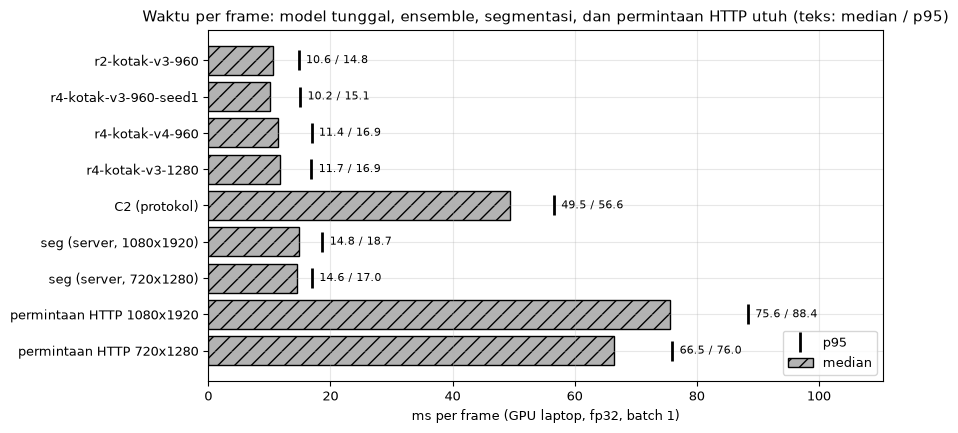

In [7]:
KP = baca_json(DATA / "test-final/ens_kecepatan_protokol.json")
KC = baca_json(DATA / "server-v2/kecepatan.json")
print("Kondisi pengukuran protokol model:")
tabel(["Item", "Nilai"], [
    ["skema daya", re.search(r"\((.*?)\)", KP["kondisi"]["skema_daya"]).group(1)],
    ["status baterai (kode Windows)", KP["kondisi"]["status_baterai"] + " (2 = tersambung charger)"],
    ["jendela aplikasi lain masih terbuka", str(len(KP["kondisi"]["jendela_terbuka"].split(","))) + " proses (hanya bisa memperlambat)"],
    ["mulai ukur", KP["mulai_ukur"]],
])
print("Kondisi uji server:")
tabel(["Item", "Nilai"], [
    ["skema daya", re.search(r"\((.*?)\)", KC["kondisi"]["skema_daya"]).group(1)],
    ["status baterai (kode Windows)", KC["kondisi"]["status_baterai"] + " (2 = tersambung charger)"],
    ["GPU sebelum ukur", KC["kondisi"]["gpu"]],
    ["jumlah frame, mulai", f"{KC['n']} frame, {KC['mulai']}"],
])
mem = KP["sendiri"]
baris = [[n, f1(v["total_ms"]), f1(v["total_ms_p95"]), f1(v["inference_ms"])] for n, v in mem.items()]
baris.append(["C2 ujung ke ujung (4 model + WBF)", f1(KP["C2"]["total_ms"]), f1(KP["C2"]["total_ms_p95"]), f"model {f1(KP['C2']['model_ms'])} + WBF {f1(KP['C2']['wbf_ms'])}"])
tabel(["Model (protokol, frame val)", "Median (ms)", "p95 (ms)", "Rincian"], baris, rata_kanan=[1, 2])
rows = []
for uk in ("1080x1920", "720x1280"):
    p = KC["proses"][uk]; h = KC["http"][uk]
    rows.append([uk, f"{KC['http'][uk]['kb_jpeg']} KB", f1(h["waktu_ms"]["median"]), f1(h["waktu_ms"]["p95"]), f1(h["bolak_balik_ms"]["median"]),
                 f1(p["decode"]["median"]), f1(p["kotak"]["median"]), f1(p["seg"]["median"]), f1(p["logika"]["median"])])
print("Uji server (HTTP utuh; kolom kanan = rincian di dalam proses, median):")
tabel(["Ukuran", "JPEG", "waktu_ms server median", "p95", "bolak-balik median", "decode", "kotak (ensemble)", "seg", "logika"], rows, rata_kanan=list(range(1, 9)))

fig, ax = plt.subplots(figsize=(9, 4.4))
nama = [n for n in mem] + ["C2 (protokol)", "seg (server, 1080x1920)", "seg (server, 720x1280)", "permintaan HTTP 1080x1920", "permintaan HTTP 720x1280"]
med = [mem[n]["total_ms"] for n in mem] + [KP["C2"]["total_ms"], KC["proses"]["1080x1920"]["seg"]["median"], KC["proses"]["720x1280"]["seg"]["median"],
                                            KC["http"]["1080x1920"]["waktu_ms"]["median"], KC["http"]["720x1280"]["waktu_ms"]["median"]]
p95 = [mem[n]["total_ms_p95"] for n in mem] + [KP["C2"]["total_ms_p95"], KC["proses"]["1080x1920"]["seg"]["p95"], KC["proses"]["720x1280"]["seg"]["p95"],
                                               KC["http"]["1080x1920"]["waktu_ms"]["p95"], KC["http"]["720x1280"]["waktu_ms"]["p95"]]
y = np.arange(len(nama))[::-1]
ax.barh(y, med, color="0.7", edgecolor="k", hatch="//", label="median")
ax.plot(p95, y, "k|", ms=14, mew=2, label="p95")
for yy, m, q in zip(y, med, p95):
    ax.text(q + 1.2, yy, f"{m:.1f} / {q:.1f}", va="center", fontsize=8)
ax.set_yticks(y); ax.set_yticklabels(nama); ax.set_xlabel("ms per frame (GPU laptop, fp32, batch 1)"); ax.set_xlim(0, max(p95) * 1.25)
ax.set_title("Waktu per frame: model tunggal, ensemble, segmentasi, dan permintaan HTTP utuh (teks: median / p95)")
ax.legend(loc="lower right"); fig.tight_layout(); plt.show()

In [8]:
m_min, m_max = min(v["total_ms"] for v in mem.values()), max(v["total_ms"] for v in mem.values())
h1 = KC["http"]["1080x1920"]["waktu_ms"]["median"]
fps_batas = 1000 / h1
display(Markdown(
    f"**Bacaan.** Satu anggota C2 butuh {f1(m_min)}-{f1(m_max)} ms, sedangkan C2 ujung ke ujung (empat model berurutan + WBF) median {f1(KP['C2']['total_ms'])} ms (p95 {f1(KP['C2']['total_ms_p95'])}), sekitar {KP['C2']['total_ms'] / (sum(v['total_ms'] for v in mem.values()) / len(mem)):.1f} kali satu model. "
    f"Segmentasi menambah sekitar {f1(KC['proses']['1080x1920']['seg']['median'])} ms. Satu permintaan HTTP utuh di server median {f1(h1)} ms pada gambar 1080x1920 dan {f1(KC['http']['720x1280']['waktu_ms']['median'])} ms pada 720x1280; "
    f"dari sisi server ini cukup untuk sekitar {fps_batas:.0f} frame per detik, sedangkan HP sendiri membatasi kiriman paling cepat tiap {JEDA_KIRIM} ms ({1000 / JEDA_KIRIM:.0f} frame/detik) dan masih ada waktu jaringan dan browser. "
    "Kelemahan: (1) ini kecepatan GPU laptop RTX 4060 dalam mode Performance dan tersambung charger, bukan kecepatan di HP atau pada laptop biasa; "
    "(2) pengukuran protokol dan uji server berbeda kondisi dan metode (rincian di dalam proses diukur di proses kedua sementara server memegang model, sehingga hanya perkiraan kasar, menurut catatan `LOG.md`); "
    f"(3) pada pengukuran pertama (mode daya lain, banyak aplikasi terbuka) C2 sempat {baca_json(DATA / 'test-final/ens_banding_val.json')['hasil']['C2']['kecepatan']['total_ms']:.1f} ms; kecepatan sangat bergantung kondisi mesin."))

**Bacaan.** Satu anggota C2 butuh 10.2-11.7 ms, sedangkan C2 ujung ke ujung (empat model berurutan + WBF) median 49.5 ms (p95 56.6), sekitar 4.5 kali satu model. Segmentasi menambah sekitar 14.8 ms. Satu permintaan HTTP utuh di server median 75.6 ms pada gambar 1080x1920 dan 66.5 ms pada 720x1280; dari sisi server ini cukup untuk sekitar 13 frame per detik, sedangkan HP sendiri membatasi kiriman paling cepat tiap 200 ms (5 frame/detik) dan masih ada waktu jaringan dan browser. Kelemahan: (1) ini kecepatan GPU laptop RTX 4060 dalam mode Performance dan tersambung charger, bukan kecepatan di HP atau pada laptop biasa; (2) pengukuran protokol dan uji server berbeda kondisi dan metode (rincian di dalam proses diukur di proses kedua sementara server memegang model, sehingga hanya perkiraan kasar, menurut catatan `LOG.md`); (3) pada pengukuran pertama (mode daya lain, banyak aplikasi terbuka) C2 sempat 80.5 ms; kecepatan sangat bergantung kondisi mesin.

## 4. Kesetaraan server dan evaluasi offline
Server memakai salinan persis kode WBF dan saringan ambang dari evaluasi, tetapi memprediksi **satu gambar per panggilan (batch 1)**, sedangkan evaluasi offline memakai batch 8. Cek ekuivalensi menjalankan jalur server di 54 frame val dan membandingkan
TP/FP/FN pada ambang terkunci dengan hasil evaluasi offline. Toleransi ditulis sebelum pengukuran.

In [9]:
EQ = baca_json(DATA / "server-v2/ekuivalensi_fp32.json")
EQH = baca_json(DATA / "server-v2/ekuivalensi_half.json")
tol = int(re.search(r"toleransi total <= (\d+)", entri("S2-pasang")).group(1))
a, s_ = EQ["acuan"], EQ["server"]
selisih = abs(a["tp"] - s_["tp"]) + abs(a["fp"] - s_["fp"]) + abs(a["fn"] - s_["fn"])
tabel(["Jalur", "TP", "FP", "FN", "Selisih total dari acuan", "Keterangan"], [
    ["offline (batch 8, acuan)", a["tp"], a["fp"], a["fn"], 0, f"{EQ['n']} frame val"],
    ["server fp32, batch 1", s_["tp"], s_["fp"], s_["fn"], selisih, f"half = {EQ['half']}; toleransi yang ditulis: <= {tol}"],
    ["server fp16 (hanya informasi)", EQH["server"]["tp"], EQH["server"]["fp"], EQH["server"]["fn"], EQH["selisih_total"], f"half = {EQH['half']}"],
], rata_kanan=[1, 2, 3, 4])
print("Frame yang jumlah deteksinya beda (fp32): ", {k: f"acuan {v[0]}, server {v[1]}" for k, v in EQ["frame_beda_jumlah"].items()})
varian = re.findall(r"(?<![\w])([A-D]) ([^;]+?) = (\d+)/(\d+)/(\d+)", entri("S3-1-diag"))
DIAG = baca(DATA / "server-v2/diag_ekuivalensi.txt")
maks_conf = max(float(v) for v in re.findall(r"maks beda conf top5: ([\d.]+)", DIAG))
print("Diagnosis penyebab selisih (model, WBF, dan ambang sama; hanya cara predict yang berbeda), dari [S3-1-diag]:")
tabel(["Varian", "Cara", "TP/FP/FN"], [[v[0], v[1].strip(), "/".join(v[2:])] for v in varian])
print("Keputusan ([S3-1-putusan] di LOG server):")
kutipan(entri("S3-1-putusan")[: entri("S3-1-putusan").index("Tabel 4 varian")].strip())

Jalur,TP,FP,FN,Selisih total dari acuan,Keterangan
"offline (batch 8, acuan)",150,76,113,0,54 frame val
"server fp32, batch 1",149,77,114,3,half = False; toleransi yang ditulis: <= 2
server fp16 (hanya informasi),149,74,114,4,half = True


Frame yang jumlah deteksinya beda (fp32):  {'dapsut_2026-10-30_02_dada_t0016028.jpg': 'acuan 5, server 6', 'dapsut_2026-10-30_02_mata_t0043027.jpg': 'acuan 3, server 2'}
Diagnosis penyebab selisih (model, WBF, dan ambang sama; hanya cara predict yang berbeda), dari [S3-1-diag]:


Varian,Cara,TP/FP/FN
A,path batch 8 (cara acuan),150/76/113
B,path batch 1,149/77/114
C,array batch 1,149/77/114
D,array batch 1 half=False,149/77/114


Keputusan ([S3-1-putusan] di LOG server):


In [10]:
beda_frame = len(EQ["frame_beda_jumlah"])
display(Markdown(
    f"**Bacaan.** Server (batch 1) memberi {s_['tp']}/{s_['fp']}/{s_['fn']} dibanding acuan {a['tp']}/{a['fp']}/{a['fn']}: selisih total {selisih}, **melebihi toleransi {tol}** yang ditulis lebih dulu, dan itu dilaporkan apa adanya. "
    f"Penyebabnya terlacak ke batch 1 vs batch 8: varian A (cara acuan) identik dengan acuan, sedangkan ketiga varian batch 1 sama-sama {s_['tp']}/{s_['fp']}/{s_['fn']}, jadi salinan WBF, saringan ambang, jalur array vs berkas, dan fp32 vs fp16 bukan sumbernya. "
f"Hanya {beda_frame} dari {EQ['n']} frame yang jumlah deteksinya berbeda (satu bertambah satu kotak, satu berkurang satu kotak), dan selisih conf terbesar pada lima kotak teratas antara batch 1 dan batch 8 adalah {maks_conf:.4f} (dari `diag_ekuivalensi.txt`). "
    "Hasil diterima oleh pemilik proyek sebagai angka server resmi tanpa penyelidikan lebih lanjut. Kelemahan: ini hanya 54 frame val (yang juga dipakai memilih model), dan perbedaan numerik batch 1 vs 8 bisa muncul di frame lain saat pemakaian nyata."))

**Bacaan.** Server (batch 1) memberi 149/77/114 dibanding acuan 150/76/113: selisih total 3, **melebihi toleransi 2** yang ditulis lebih dulu, dan itu dilaporkan apa adanya. Penyebabnya terlacak ke batch 1 vs batch 8: varian A (cara acuan) identik dengan acuan, sedangkan ketiga varian batch 1 sama-sama 149/77/114, jadi salinan WBF, saringan ambang, jalur array vs berkas, dan fp32 vs fp16 bukan sumbernya. Hanya 2 dari 54 frame yang jumlah deteksinya berbeda (satu bertambah satu kotak, satu berkurang satu kotak), dan selisih conf terbesar pada lima kotak teratas antara batch 1 dan batch 8 adalah 0.0977 (dari `diag_ekuivalensi.txt`). Hasil diterima oleh pemilik proyek sebagai angka server resmi tanpa penyelidikan lebih lanjut. Kelemahan: ini hanya 54 frame val (yang juga dipakai memilih model), dan perbedaan numerik batch 1 vs 8 bisa muncul di frame lain saat pemakaian nyata.

### 4.1 Uji HTTP
`uji_http.txt` mencatat uji kontrak API pada server yang dijalankan di laptop (tanpa model baru).

In [11]:
ht = baca(DATA / "server-v2/uji_http.txt")
n_valid = len(re.findall(r"-> VALID", ht))
baris = [
    ["GET /api/status", "200" if "status: 200" in ht else "tidak 200", re.search(r"status: 200 (.*)", ht).group(1)],
    ["GET / (halaman web)", re.search(r"GET /: (\d+)", ht).group(1), "isi identik dengan index.html" if "identik index.html Kenzu: True" in ht else "BERBEDA"],
    ["POST gambar valid (beberapa lokasi, 640 px)", f"{n_valid} kasus", "semua balasan sesuai kontrak (VALID)"],
    ["POST tanpa header X-Sesi", re.search(r"tanpa X-Sesi: (\d+)", ht).group(1), "memakai sesi 'default'"],
    ["POST body kosong", re.search(r"body kosong: (\d+)", ht).group(1), re.search(r"body kosong: \d+ (.*)", ht).group(1)],
    ["POST body bukan gambar", re.search(r"body sampah: (\d+)", ht).group(1), re.search(r"body sampah: \d+ (.*)", ht).group(1)],
    ["Ringkasan berkas", "SEMUA LULUS" if "SEMUA LULUS" in ht else "ADA YANG GAGAL", ""],
]
tabel(["Uji", "Hasil", "Catatan"], baris)

Uji,Hasil,Catatan
GET /api/status,200,"{'siap': True, 'model': 'ensemble-final', 'versi_kontrak': 1}"
GET / (halaman web),200,isi identik dengan index.html
"POST gambar valid (beberapa lokasi, 640 px)",3 kasus,semua balasan sesuai kontrak (VALID)
POST tanpa header X-Sesi,200,memakai sesi 'default'
POST body kosong,400,{'error': 'Gambar kosong.'}
POST body bukan gambar,400,{'error': 'Format gambar tidak valid.'}
Ringkasan berkas,SEMUA LULUS,


## 5. Ablasi aturan peringatan (tanpa pelatihan)
Setelah uji lapangan terlihat terlalu banyak peringatan tangga palsu, tiga aturan diuji **offline** tanpa melatih ulang: **A** jeda 8 detik untuk benda ringan (di suara), **B** objek "jauh" tidak jadi peringatan bila seg kosong, **C** "Tangga di depan" (seg) harus 3 dari 3 frame.
Model dijalankan **satu kali** per frame (hasil disimpan), lalu satu mesin logika per konfigurasi memproses hasil yang sama. K0 = semua mati (lama); K1 = C; K2 = K1 + ambang tangga seg 10%; K3 = K1 + B; K4 = K2 + B.
Data: KAMPUS = frame-blur non-test (setiap folder satu sesi; bukan rekaman kontinu), RUMAH = satu rekaman HP. Angka dihitung dari `ablasi_frame.csv` dan dicocokkan dengan `hasil_ablasi.md`.

In [12]:
AB = baca_csv(DATA / "aturan-peringatan/ablasi_frame.csv")
ABS = baca(DATA / "aturan-peringatan/hasil_ablasi.md")
KS = ["K0", "K1", "K2", "K3", "K4"]
# definisi konfigurasi dibaca dari kode ablasi.py (hanya diurai, tidak dijalankan)
tree = ast.parse(baca(DATA / "aturan-peringatan/ablasi.py"))
KONFIG = next(ast.literal_eval(n.value) for n in tree.body if isinstance(n, ast.Assign) and getattr(n.targets[0], "id", "") == "KONFIG")
print("Konfigurasi ablasi (override terhadap config.yaml dasar, dari ablasi.py):")
tabel(["Konfigurasi", "Override"], [[k, json.dumps(v) if v else "(tidak ada: semua aturan baru mati)"] for k, v in KONFIG])

def menit(rs):
    by = collections.defaultdict(list)
    for x in rs:
        by[x["sesi"]].append(float(x["ts"]))
    return sum(max(v) - min(v) for v in by.values()) / 60

RUJUK = re.search(r"tangga ASLI di rumah kira-kira frame (\d+)-(\d+) dan (\d+)-(\d+)", ABS)
RENT = [(int(RUJUK.group(1)), int(RUJUK.group(2))), (int(RUJUK.group(3)), int(RUJUK.group(4)))]
def nyata(i):
    return any(a <= i <= b for a, b in RENT)

HASIL = {}
for S in ("KAMPUS", "RUMAH"):
    rs = [x for x in AB if x["set"] == S]
    mn = menit(rs)
    HASIL[S] = dict(n=len(rs), menit=mn, K={})
    for K in KS:
        p = [x[K + "_pesan"] for x in rs]
        d = dict(
            apa_pun=sum(1 for t in p if t),
            tangga_seg=sum(1 for t in p if t == "Tangga di depan"),
            kotak_tangga=sum(1 for t in p if t.startswith("Tangga") and t != "Tangga di depan"),
            kotak_tangga_jauh=sum(1 for t in p if t.startswith("Tangga") and t != "Tangga di depan" and t.endswith("jauh")),
            tidak_terlihat=sum(1 for t in p if t == "Hati-hati, jalur tidak terlihat"),
            ucap_mati=sum(int(x[K + "_ucap_A_mati"]) for x in rs), ucap_nyala=sum(int(x[K + "_ucap_A_nyala"]) for x in rs),
        )
        if S == "KAMPUS":
            d["tangga_salah"] = sum(1 for x in rs if x[K + "_pesan"].startswith("Tangga") and not x["sesi"].startswith("tangga-naik"))
            d["tangga_benar"] = sum(1 for x in rs if x[K + "_pesan"].startswith("Tangga") and x["sesi"].startswith("tangga-naik"))
        else:
            d["tangga_salah"] = sum(1 for x in rs if x[K + "_pesan"].startswith("Tangga") and not nyata(int(x["frame"])))
            d["tangga_benar"] = sum(1 for x in rs if x[K + "_pesan"].startswith("Tangga") and nyata(int(x["frame"])))
        HASIL[S]["K"][K] = d
print(f"KAMPUS: {HASIL['KAMPUS']['n']} frame, {HASIL['KAMPUS']['menit']:.1f} menit; RUMAH: {HASIL['RUMAH']['n']} frame, {HASIL['RUMAH']['menit']:.1f} menit. "
      f"Rujukan tangga asli di RUMAH (dari catatan di hasil_ablasi.md): frame {RENT[0][0]}-{RENT[0][1]} dan {RENT[1][0]}-{RENT[1][1]}.")
for S in ("KAMPUS", "RUMAH"):
    print()
    print(f"{S}: jumlah frame menurut jenis peringatan")
    jenis = [("frame dengan peringatan apa pun", "apa_pun"), ("'Tangga di depan' (seg)", "tangga_seg"), ("kotak Tangga (semua)", "kotak_tangga"), ("  - kotak Tangga jauh", "kotak_tangga_jauh"),
             ("'jalur tidak terlihat'", "tidak_terlihat"),
             ("tangga SALAH (" + ("folder bukan tangga-naik" if S == "KAMPUS" else "di luar rentang rujukan") + ")", "tangga_salah"),
             ("tangga BENAR (" + ("folder tangga-naik" if S == "KAMPUS" else "di rentang rujukan") + ")", "tangga_benar"),
             ("diucapkan, A mati", "ucap_mati"), ("diucapkan, A nyala (jeda 8 dtk)", "ucap_nyala")]
    tabel(["Jenis"] + KS, [[n] + [HASIL[S]["K"][K][k] for K in KS] for n, k in jenis], rata_kanan=[1, 2, 3, 4, 5])

Konfigurasi ablasi (override terhadap config.yaml dasar, dari ablasi.py):

Konfigurasi,Override
K0,(tidak ada: semua aturan baru mati)
K1,"{""seg_tangga_stabil_minimal"": 3}"
K2,"{""seg_tangga_stabil_minimal"": 3, ""seg_tangga_min"": 0.1}"
K3,"{""seg_tangga_stabil_minimal"": 3, ""jauh_butuh_seg"": true}"
K4,"{""seg_tangga_stabil_minimal"": 3, ""seg_tangga_min"": 0.1, ""jauh_butuh_seg"": true}"


KAMPUS: 3790 frame, 62.6 menit; RUMAH: 985 frame, 5.0 menit. Rujukan tangga asli di RUMAH (dari catatan di hasil_ablasi.md): frame 440-470 dan 930-985.

KAMPUS: jumlah frame menurut jenis peringatan


Jenis,K0,K1,K2,K3,K4
frame dengan peringatan apa pun,2162,2145,2147,2141,2143
'Tangga di depan' (seg),31,13,13,13,13
kotak Tangga (semua),189,189,189,189,189
- kotak Tangga jauh,8,8,8,8,8
'jalur tidak terlihat',74,74,74,77,77
tangga SALAH (folder bukan tangga-naik),90,75,75,75,75
tangga BENAR (folder tangga-naik),130,127,127,127,127
"diucapkan, A mati",1058,1047,1047,1045,1045
"diucapkan, A nyala (jeda 8 dtk)",985,974,974,973,973



RUMAH: jumlah frame menurut jenis peringatan


Jenis,K0,K1,K2,K3,K4
frame dengan peringatan apa pun,706,702,703,696,697
'Tangga di depan' (seg),30,19,18,19,18
kotak Tangga (semua),73,73,73,60,60
- kotak Tangga jauh,21,21,21,8,8
'jalur tidak terlihat',141,141,141,148,148
tangga SALAH (di luar rentang rujukan),51,40,39,27,26
tangga BENAR (di rentang rujukan),52,52,52,52,52
"diucapkan, A mati",198,194,195,196,197
"diucapkan, A nyala (jeda 8 dtk)",130,125,125,127,127


In [13]:
# pemeriksaan silang dengan hasil_ablasi.md (apa adanya)
cocok, beda = 0, []
BAGIAN = {"KAMPUS": ABS[ABS.index("## KAMPUS"):ABS.index("## RUMAH")], "RUMAH": ABS[ABS.index("## RUMAH"):]}
for S, judul in (("KAMPUS", "## KAMPUS"), ("RUMAH", "## RUMAH")):
    t = tabel_md(BAGIAN[S], judul)
    ket = {r[0].strip(" -"): r[1:6] for r in t[1:] if len(r) >= 6}
    peta = {"frame dengan peringatan apa pun": "apa_pun", "Tangga di depan (seg)": "tangga_seg", "Kotak Tangga (semua)": "kotak_tangga", "Kotak Tangga jauh": "kotak_tangga_jauh", "Jalur tidak terlihat": "tidak_terlihat"}
    for nm, k in peta.items():
        for i, K in enumerate(KS):
            md = int(ket[nm][i]); hit = HASIL[S]["K"][K][k]
            if md == hit:
                cocok += 1
            else:
                beda.append((S, nm, K, md, hit))
    ts = tabel_md(BAGIAN[S], "Peringatan diucapkan per menit")
    for lbl, kk in (("A mati", "ucap_mati"), ("A nyala", "ucap_nyala")):
        baris_md = next(r for r in ts if r[0] == lbl)
        for i, K in enumerate(KS):
            md = int(re.match(r"(\d+)", baris_md[1 + i]).group(1)); hit = HASIL[S]["K"][K][kk]
            if md == hit:
                cocok += 1
            else:
                beda.append((S, lbl, K, md, hit))
    mm = float(re.search(rf"{S}\s+\(\d+ frame, ([\d.]+) menit\)", ABS).group(1))
    if abs(mm - HASIL[S]["menit"]) < 0.05:
        cocok += 1
    else:
        beda.append((S, "menit", "-", mm, round(HASIL[S]["menit"], 1)))
print(f"Pemeriksaan silang csv vs hasil_ablasi.md: {cocok} sel cocok, {len(beda)} berbeda.", beda or "")

Pemeriksaan silang csv vs hasil_ablasi.md: 72 sel cocok, 0 berbeda. 


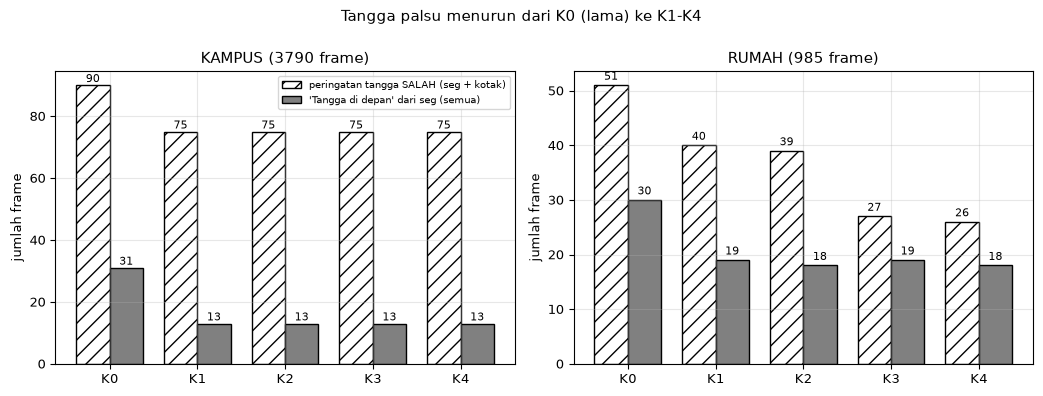

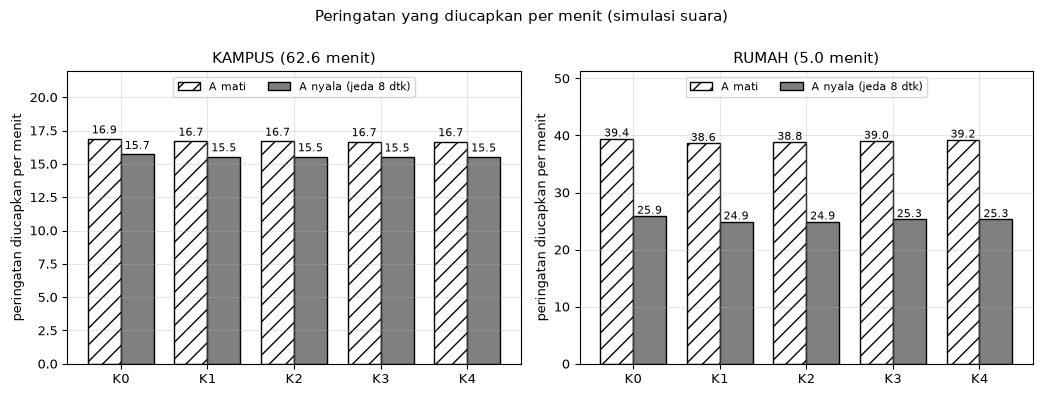

In [14]:
fig, axs = plt.subplots(1, 2, figsize=(10.5, 3.9))
for ax, S in zip(axs, ("KAMPUS", "RUMAH")):
    sal = [HASIL[S]["K"][K]["tangga_salah"] for K in KS]; sg = [HASIL[S]["K"][K]["tangga_seg"] for K in KS]
    x = np.arange(len(KS)); w = 0.38
    ax.bar(x - w / 2, sal, w, color="white", edgecolor="k", hatch="//", label="peringatan tangga SALAH (seg + kotak)")
    ax.bar(x + w / 2, sg, w, color="0.5", edgecolor="k", label="'Tangga di depan' dari seg (semua)")
    for xi, v in zip(x - w / 2, sal):
        ax.text(xi, v + 1, str(v), ha="center", fontsize=8)
    for xi, v in zip(x + w / 2, sg):
        ax.text(xi, v + 1, str(v), ha="center", fontsize=8)
    ax.set_xticks(x); ax.set_xticklabels(KS); ax.set_ylabel("jumlah frame"); ax.set_title(f"{S} ({HASIL[S]['n']} frame)")
axs[0].legend(fontsize=7, loc="upper right")
fig.suptitle("Tangga palsu menurun dari K0 (lama) ke K1-K4", y=1.0); fig.tight_layout(); plt.show()

fig, axs = plt.subplots(1, 2, figsize=(10.5, 3.9), sharey=False)
for ax, S in zip(axs, ("KAMPUS", "RUMAH")):
    x = np.arange(len(KS)); w = 0.38; mn = HASIL[S]["menit"]
    pm = [HASIL[S]["K"][K]["ucap_mati"] / mn for K in KS]; pn = [HASIL[S]["K"][K]["ucap_nyala"] / mn for K in KS]
    ax.bar(x - w / 2, pm, w, color="white", edgecolor="k", hatch="//", label="A mati")
    ax.bar(x + w / 2, pn, w, color="0.5", edgecolor="k", label="A nyala (jeda 8 dtk)")
    for xi, v in zip(x - w / 2, pm):
        ax.text(xi, v + 0.4, f"{v:.1f}", ha="center", fontsize=8)
    for xi, v in zip(x + w / 2, pn):
        ax.text(xi, v + 0.4, f"{v:.1f}", ha="center", fontsize=8)
    ax.set_ylim(0, max(pm + pn) * 1.3)
    ax.set_xticks(x); ax.set_xticklabels(KS); ax.set_ylabel("peringatan diucapkan per menit"); ax.set_title(f"{S} ({mn:.1f} menit)")
    ax.legend(fontsize=8, loc="upper center", ncol=2)
fig.suptitle("Peringatan yang diucapkan per menit (simulasi suara)", y=1.0); fig.tight_layout(); plt.show()

In [15]:
# konfigurasi terpilih: bandingkan config.yaml dan suara.js dengan K3 + A
k3 = dict(KONFIG)["K3"]
sama = {k: CFG.get(k) == v for k, v in k3.items()}
aA = JEDA_RINGAN
ks, kr = HASIL["KAMPUS"]["K"], HASIL["RUMAH"]["K"]
display(Markdown("**Konfigurasi yang dipakai server dan HP saat ini** dibandingkan dengan K3 + A:"))
tabel(["Parameter", "Nilai K3 (ablasi.py)", "Nilai saat ini (config.yaml / suara.js)", "Sama?"],
      [[k, v, CFG.get(k), "ya" if sama[k] else "TIDAK"] for k, v in k3.items()] + [["jeda benda ringan (A), ms", "8000 (JEDA_RINGAN_MS di ablasi.py)", JEDA_RINGAN, "ya" if JEDA_RINGAN == 8000 else "TIDAK"]])
tidak_ter = (HASIL["KAMPUS"]["K"]["K3"]["tidak_terlihat"] - HASIL["KAMPUS"]["K"]["K0"]["tidak_terlihat"], HASIL["RUMAH"]["K"]["K3"]["tidak_terlihat"] - HASIL["RUMAH"]["K"]["K0"]["tidak_terlihat"])
display(Markdown(
    f"**Bacaan.** Aturan C (K1) menurunkan 'Tangga di depan' dari seg di KAMPUS dari {ks['K0']['tangga_seg']} ke {ks['K1']['tangga_seg']} frame dan di RUMAH dari {kr['K0']['tangga_seg']} ke {kr['K1']['tangga_seg']}; "
    f"frame tangga yang salah di KAMPUS turun dari {ks['K0']['tangga_salah']} ke {ks['K1']['tangga_salah']}, sementara frame tangga yang benar (folder tangga-naik) hanya berubah dari {ks['K0']['tangga_benar']} ke {ks['K1']['tangga_benar']}. "
    f"Aturan B (K3) menghilangkan kotak 'Tangga' yang jauh di RUMAH ({kr['K1']['kotak_tangga']} -> {kr['K3']['kotak_tangga']} frame) tetapi di KAMPUS tidak mengubahnya ({ks['K1']['kotak_tangga']} -> {ks['K3']['kotak_tangga']}). "
    f"Harga B: frame 'jalur tidak terlihat' bertambah ({tidak_ter[0]:+d} di KAMPUS, {tidak_ter[1]:+d} di RUMAH). Aturan A memangkas peringatan yang diucapkan dari {ks['K3']['ucap_mati'] / HASIL['KAMPUS']['menit']:.1f} ke {ks['K3']['ucap_nyala'] / HASIL['KAMPUS']['menit']:.1f} per menit di KAMPUS "
    f"dan dari {kr['K3']['ucap_mati'] / HASIL['RUMAH']['menit']:.1f} ke {kr['K3']['ucap_nyala'] / HASIL['RUMAH']['menit']:.1f} per menit di RUMAH. K3 + A dipilih (konfigurasi di atas cocok dengan {'seluruh' if all(sama.values()) else 'sebagian'} nilai K3). "
    "Kelemahan: ablasi ini offline pada data yang sama dengan yang dipakai memilih aturan, tanpa label kebenaran per frame; 'tangga salah' di KAMPUS dihitung dari nama folder (hanya folder tangga-naik dianggap tangga asli), dan di RUMAH dari rentang rujukan yang dicatat tangan. "
    "Jumlah yang diucapkan per menit adalah simulasi suara pada frame yang tidak kontinu, bukan pengukuran pemakaian nyata."))

**Konfigurasi yang dipakai server dan HP saat ini** dibandingkan dengan K3 + A:

Parameter,Nilai K3 (ablasi.py),Nilai saat ini (config.yaml / suara.js),Sama?
seg_tangga_stabil_minimal,3,3,ya
jauh_butuh_seg,True,True,ya
"jeda benda ringan (A), ms",8000 (JEDA_RINGAN_MS di ablasi.py),8000,ya


**Bacaan.** Aturan C (K1) menurunkan 'Tangga di depan' dari seg di KAMPUS dari 31 ke 13 frame dan di RUMAH dari 30 ke 19; frame tangga yang salah di KAMPUS turun dari 90 ke 75, sementara frame tangga yang benar (folder tangga-naik) hanya berubah dari 130 ke 127. Aturan B (K3) menghilangkan kotak 'Tangga' yang jauh di RUMAH (73 -> 60 frame) tetapi di KAMPUS tidak mengubahnya (189 -> 189). Harga B: frame 'jalur tidak terlihat' bertambah (+3 di KAMPUS, +7 di RUMAH). Aturan A memangkas peringatan yang diucapkan dari 16.7 ke 15.5 per menit di KAMPUS dan dari 39.0 ke 25.3 per menit di RUMAH. K3 + A dipilih (konfigurasi di atas cocok dengan seluruh nilai K3). Kelemahan: ablasi ini offline pada data yang sama dengan yang dipakai memilih aturan, tanpa label kebenaran per frame; 'tangga salah' di KAMPUS dihitung dari nama folder (hanya folder tangga-naik dianggap tangga asli), dan di RUMAH dari rentang rujukan yang dicatat tangan. Jumlah yang diucapkan per menit adalah simulasi suara pada frame yang tidak kontinu, bukan pengukuran pemakaian nyata.

## 6. Ambang kendaraan: 0,10 menjadi 0,25
Saat uji pemakaian, deteksi 'kendaraan' palsu di dalam ruangan menimbulkan alarm merah (tingkat 3). Ambang kendaraan kemudian dinaikkan dari 0,10 ke 0,25 di `config.yaml`. Di sini dihitung **tanpa menjalankan model** berapa frame yang memuat kotak kendaraan pada
ambang 0,10 vs 0,25, memakai `cache_deteksi.pkl` (hasil deteksi tersimpan dari ablasi). Struktur berkas diperiksa dulu.

In [16]:
CACHE = pickle.loads((DATA / "aturan-peringatan/cache_deteksi.pkl").read_bytes())
print("Struktur cache_deteksi.pkl (pickle berisi list; hanya butuh numpy, tanpa torch):")
print(f"  list dengan {len(CACHE)} elemen; satu elemen per frame, urutan sama dengan baris ablasi_frame.csv ({len(AB)} baris)")
e0 = next(x for x in CACHE if x["objek"])
print(f"  tiap elemen: dict dengan kunci {sorted(e0.keys())}")
print(f"  'objek': list kotak hasil server (setelah WBF dan saringan ambang pada saat itu); kunci per kotak: {sorted(e0['objek'][0].keys())}, kotak = [x1, y1, x2, y2] ternormalisasi 0-1")
print(f"  'kelas_seg': list id kelas seg; 'nama_kelas_seg': {e0['nama_kelas_seg']}; 'waktu_ms': float; 'mask': (bit mask terkompresi (np.packbits), bentuk) atau None")
assert len(CACHE) == len(AB)
cek_seg = sum(1 for x, r in zip(CACHE, AB) if len(x["kelas_seg"]) == int(r["n_seg"]))
print(f"  pemeriksaan urutan: jumlah mask seg di cache sama dengan kolom n_seg di csv pada {cek_seg} dari {len(AB)} frame")
conf_k = [o["conf"] for x in CACHE for o in x["objek"] if o["kelas"] == "kendaraan"]
print(f"  kotak kendaraan di cache: {len(conf_k)}; conf terkecil {min(conf_k):.4f} (cache dibuat dengan ambang kendaraan {min(conf_k):.2f}, sehingga membandingkan >= 0,10 dengan >= 0,25 valid)")

def lokasi(sesi):
    return re.sub(r"_20\d\d-\d\d-\d\d_.*", "", sesi)

per = collections.OrderedDict()
for x, r in zip(CACHE, AB):
    g = lokasi(r["sesi"]) if r["set"] == "KAMPUS" else "rumah (rekaman sore)"
    c = [o["conf"] for o in x["objek"] if o["kelas"] == "kendaraan"]
    d = per.setdefault(g, [0, 0, 0, r["set"]])
    d[0] += 1
    d[1] += any(v >= 0.10 for v in c)
    d[2] += any(v >= 0.25 for v in c)
del CACHE

Struktur cache_deteksi.pkl (pickle berisi list; hanya butuh numpy, tanpa torch):
  list dengan 4775 elemen; satu elemen per frame, urutan sama dengan baris ablasi_frame.csv (4775 baris)
  tiap elemen: dict dengan kunci ['kelas_seg', 'mask', 'nama_kelas_seg', 'objek', 'waktu_ms']
  'objek': list kotak hasil server (setelah WBF dan saringan ambang pada saat itu); kunci per kotak: ['conf', 'kelas', 'kotak'], kotak = [x1, y1, x2, y2] ternormalisasi 0-1
  'kelas_seg': list id kelas seg; 'nama_kelas_seg': {0: 'jalur_jalan', 1: 'jalan_kendaraan', 2: 'tangga'}; 'waktu_ms': float; 'mask': (bit mask terkompresi (np.packbits), bentuk) atau None
  pemeriksaan urutan: jumlah mask seg di cache sama dengan kolom n_seg di csv pada 4775 dari 4775 frame
  kotak kendaraan di cache: 7219; conf terkecil 0.1000 (cache dibuat dengan ambang kendaraan 0.10, sehingga membandingkan >= 0,10 dengan >= 0,25 valid)


In [17]:
LUAR = ["parkiran-motor-b1-ubm-tower", "jalanan-ubm", "dapsut", "samping-ubm", "halaman-ubm"]
DALAM = ["lab-iota1-lt9-ubm-tower", "lab1-lt5-alfa-tower", "lorong-lt5-alfa-tower", "lorong-lt9-ubm-tower", "perpus-lt9-ubm-tower"]
LAIN = [g for g, v in per.items() if v[3] == "KAMPUS" and g not in LUAR + DALAM]
def jumlah(gs):
    return [sum(per[g][i] for g in gs) for i in range(3)]
def baris_v(nama, gs):
    n, a_, b_ = jumlah(gs)
    return [nama, n, a_, b_, f"{a_ - b_} ({100 * (a_ - b_) / a_:.1f}%)" if a_ else "-"]
baris = [baris_v(g, [g]) for g in LUAR]
baris += [baris_v("DALAM RUANGAN (lab, lorong, perpus)", DALAM)]
baris += [baris_v("lainnya: " + ", ".join(g.split("-ubm")[0].split("-alfa")[0] for g in LAIN), LAIN)]
baris += [baris_v("rumah (rekaman sore, 2 sesi)", ["rumah (rekaman sore)"])]
baris += [baris_v("SEMUA KAMPUS", [g for g in per if per[g][3] == "KAMPUS"])]
print("Frame yang memuat kotak kendaraan, ambang 0,10 vs 0,25:")
tabel(["Kelompok / lokasi", "Frame", "Kendaraan >= 0,10", "Kendaraan >= 0,25", "Hilang"], baris, rata_kanan=[1, 2, 3, 4])
print()
print("Per lokasi kampus (semua lokasi, tanpa pengelompokan):")
tabel(["Lokasi", "Frame", ">= 0,10", ">= 0,25"], [[g, v[0], v[1], v[2]] for g, v in per.items() if v[3] == "KAMPUS"], rata_kanan=[1, 2, 3])

Frame yang memuat kotak kendaraan, ambang 0,10 vs 0,25:


Kelompok / lokasi,Frame,"Kendaraan >= 0,10","Kendaraan >= 0,25",Hilang
parkiran-motor-b1-ubm-tower,700,593,585,8 (1.3%)
jalanan-ubm,246,158,147,11 (7.0%)
dapsut,381,236,218,18 (7.6%)
samping-ubm,396,31,22,9 (29.0%)
halaman-ubm,196,1,0,1 (100.0%)
"DALAM RUANGAN (lab, lorong, perpus)",1121,13,5,8 (61.5%)
"lainnya: alfamart-lt2, lorong-lt3-eskalator, tangga-naik, tangga-naik-lt3, tangga-naik-lt9-lt10",750,46,27,19 (41.3%)
"rumah (rekaman sore, 2 sesi)",985,142,95,47 (33.1%)
SEMUA KAMPUS,3790,1078,1004,74 (6.9%)



Per lokasi kampus (semua lokasi, tanpa pengelompokan):


Lokasi,Frame,">= 0,10",">= 0,25"
alfamart-lt2,81,8,2
dapsut,381,236,218
halaman-ubm,196,1,0
jalanan-ubm,246,158,147
lab-iota1-lt9-ubm-tower,140,1,1
lab1-lt5-alfa-tower,91,2,1
lorong-lt3-eskalator-alfa-tower,432,35,24
lorong-lt5-alfa-tower,197,0,0
lorong-lt9-ubm-tower,279,1,0
parkiran-motor-b1-ubm-tower,700,593,585


In [18]:
luar_h = [(g, per[g][1], per[g][2]) for g in LUAR if per[g][1] >= 50]
drop = [100 * (a_ - b_) / a_ for _, a_, b_ in luar_h]
d_n, d_a, d_b = jumlah(DALAM); r_n, r_a, r_b = per["rumah (rekaman sore)"][:3]
display(Markdown(
    f"**Bacaan.** Di lokasi kampus yang benar-benar punya kendaraan ({', '.join(g.split('-')[0] for g, _, _ in luar_h)}), menaikkan ambang ke 0,25 hanya menghilangkan {min(drop):.1f}-{max(drop):.1f}% frame berkendaraan, jadi deteksi kendaraan asli hampir tidak terpengaruh; lokasi dengan sedikit frame berkendaraan terdampak lebih besar secara relatif (samping-ubm {per['samping-ubm'][1]} -> {per['samping-ubm'][2]}, {100 * (per['samping-ubm'][1] - per['samping-ubm'][2]) / per['samping-ubm'][1]:.0f}%). "
    f"Di dalam ruangan (lab, lorong, perpus) frame berkendaraan turun dari {d_a} ke {d_b} ({100 * (d_a - d_b) / d_a:.0f}% hilang), dan di rekaman rumah dari {r_a} ke {r_b} ({100 * (r_a - r_b) / r_a:.0f}% hilang): sebagian besar kotak kendaraan di dalam ruangan adalah deteksi lemah (conf 0,10-0,25). "
    "Kelemahan: (1) tidak ada label kebenaran, jadi 'hilang' tidak otomatis berarti palsu; sebagian bisa kendaraan asli yang jauh atau tertutup. "
    "(2) Pengelompokan 'dalam ruangan' adalah definisi saya dari nama lokasi (lab, lorong, perpus; tanpa eskalator, tangga, dan toko) dan tidak tercatat di berkas sumber; tabel per lokasi di atas memuat semuanya. "
    "(3) Cache memuat frame kampus non-test dan satu rekaman rumah; belum ada data kendaraan lain."))

**Bacaan.** Di lokasi kampus yang benar-benar punya kendaraan (parkiran, jalanan, dapsut), menaikkan ambang ke 0,25 hanya menghilangkan 1.3-7.6% frame berkendaraan, jadi deteksi kendaraan asli hampir tidak terpengaruh; lokasi dengan sedikit frame berkendaraan terdampak lebih besar secara relatif (samping-ubm 31 -> 22, 29%). Di dalam ruangan (lab, lorong, perpus) frame berkendaraan turun dari 13 ke 5 (62% hilang), dan di rekaman rumah dari 142 ke 95 (33% hilang): sebagian besar kotak kendaraan di dalam ruangan adalah deteksi lemah (conf 0,10-0,25). Kelemahan: (1) tidak ada label kebenaran, jadi 'hilang' tidak otomatis berarti palsu; sebagian bisa kendaraan asli yang jauh atau tertutup. (2) Pengelompokan 'dalam ruangan' adalah definisi saya dari nama lokasi (lab, lorong, perpus; tanpa eskalator, tangga, dan toko) dan tidak tercatat di berkas sumber; tabel per lokasi di atas memuat semuanya. (3) Cache memuat frame kampus non-test dan satu rekaman rumah; belum ada data kendaraan lain.

## 7. Kamera menempel tembok: 'jalur tidak terlihat' (hanya angka)
Saat HP menempel atau sangat dekat ke tembok atau pintu, model segmentasi tidak mengeluarkan satu pun mask. Server menanggapinya dengan peringatan "Hati-hati, jalur tidak terlihat" bila **3 frame berturut-turut** kosong.
Diagnosis D1 (frame tunggal) dan D2 (urutan frame kampus) disimpan sebagai CSV; hanya angka yang dipakai di sini, tidak ada gambar.

In [19]:
D2 = baca_csv(DATA / "diagnosa-mepet/d2_ringkasan.csv")
D1 = baca_csv(DATA / "diagnosa-mepet/hasil.csv")
n_fr = sum(int(x["frames"]) for x in D2); n_kos = sum(int(x["kosong"]) for x in D2)
n_tt = sum(int(x["n_tidak_terlihat"]) for x in D2); n_th = sum(int(x["n_terhalang"]) for x in D2); mx = max(int(x["streak_maks"]) for x in D2)
urut = sorted(D2, key=lambda x: -int(x["n_tidak_terlihat"]))
print("D2: urutan frame kampus non-test (d2_ringkasan.csv, satu baris per rekaman):")
tabel(["Ukuran", "Nilai"], [
    ["rekaman (folder)", len(D2)], ["frame total", n_fr], ["frame dengan seg KOSONG", f"{n_kos} ({100 * n_kos / n_fr:.1f}%)"],
    ["frame 'jalur tidak terlihat' (3 berturut-turut kosong)", f"{n_tt} ({100 * n_tt / n_fr:.1f}%)"], ["frame 'jalur terhalang'", n_th], ["rentetan kosong terpanjang (frame)", mx],
    ["rekaman tanpa satu pun frame kosong", sum(1 for x in D2 if int(x["kosong"]) == 0)],
])
print("Lima rekaman dengan 'jalur tidak terlihat' terbanyak:")
tabel(["Rekaman", "Frame", "Kosong", "% kosong", "Rentetan maks", "Jalur tidak terlihat"], [[x["folder"], x["frames"], x["kosong"], x["kosong_pct"], x["streak_maks"], x["n_tidak_terlihat"]] for x in urut[:5]], rata_kanan=[1, 2, 3, 4, 5])
foto = [x for x in D1 if x["sumber"] == "foto"]
base = [x for x in D1 if x["sumber"] != "foto"]
st_f = collections.Counter(x["status"] for x in foto)
n_foto0 = sum(1 for x in foto if int(x["n_instance"]) == 0)
print(f"D1: {len(foto)} foto uji menempel tembok/pilar/pintu: status {dict(st_f)}; {n_foto0} dari {len(foto)} tanpa satu pun mask seg. Pembanding: {len(base)} frame kampus: status {dict(collections.Counter(x['status'] for x in base))}.")
# kecocokan dengan ablasi
tt_ablasi = HASIL["KAMPUS"]["K"]["K0"]["tidak_terlihat"]
print(f"Pemeriksaan silang: 'jalur tidak terlihat' di D2 = {n_tt} frame; di ablasi K0 KAMPUS = {tt_ablasi} frame -> {'SAMA' if n_tt == tt_ablasi else 'BEDA'}")

D2: urutan frame kampus non-test (d2_ringkasan.csv, satu baris per rekaman):


Ukuran,Nilai
rekaman (folder),41
frame total,3790
frame dengan seg KOSONG,316 (8.3%)
frame 'jalur tidak terlihat' (3 berturut-turut kosong),74 (2.0%)
frame 'jalur terhalang',207
rentetan kosong terpanjang (frame),15
rekaman tanpa satu pun frame kosong,6


Lima rekaman dengan 'jalur tidak terlihat' terbanyak:


Rekaman,Frame,Kosong,% kosong,Rentetan maks,Jalur tidak terlihat
lorong-lt3-eskalator-alfa-tower_2026-10-30_01_mata,215,32,14.9,15,20
lorong-lt3-eskalator-alfa-tower_2026-10-30_01_dada,217,29,13.4,12,13
perpus-lt9-ubm-tower_2026-10-30_01_mata,213,38,17.8,5,10
perpus-lt9-ubm-tower_2026-10-30_01_dada,201,56,27.9,5,5
lab1-lt5-alfa-tower_2026-10-30_02_mata,22,11,50.0,5,4


D1: 5 foto uji menempel tembok/pilar/pintu: status {'tidak_jelas': 5}; 4 dari 5 tanpa satu pun mask seg. Pembanding: 30 frame kampus: status {'terbuka': 16, 'tidak_jelas': 5, 'terhalang': 9}.
Pemeriksaan silang: 'jalur tidak terlihat' di D2 = 74 frame; di ablasi K0 KAMPUS = 74 frame -> SAMA


In [20]:
display(Markdown(
    f"**Bacaan.** Dari {n_fr} frame kampus non-test, {n_kos} ({100 * n_kos / n_fr:.1f}%) tidak punya satu pun mask seg, dan {n_tt} frame ({100 * n_tt / n_fr:.1f}%) menjadi 'jalur tidak terlihat' setelah aturan tiga berturut-turut; "
    f"rentetan kosong terpanjang {mx} frame, terkonsentrasi di beberapa rekaman (terbanyak: {', '.join(x['folder'].split('_')[0] + ' (' + x['folder'].split('_')[-1] + ')' for x in urut[:3])}).Foto uji yang menempel tembok: status {dict(st_f)}, {n_foto0} dari {len(foto)} tanpa mask sama sekali. "
    "Arti praktisnya: peringatan ini muncul benar saat kamera mepet, tetapi juga bisa muncul di lorong biasa saat seg gagal sesaat. "
    "Kelemahan: tidak ada label 'kamera mepet' per frame, jadi tidak diketahui berapa dari frame kosong itu benar-benar mepet; foto uji hanya lima."))

**Bacaan.** Dari 3790 frame kampus non-test, 316 (8.3%) tidak punya satu pun mask seg, dan 74 frame (2.0%) menjadi 'jalur tidak terlihat' setelah aturan tiga berturut-turut; rentetan kosong terpanjang 15 frame, terkonsentrasi di beberapa rekaman (terbanyak: lorong-lt3-eskalator-alfa-tower (mata), lorong-lt3-eskalator-alfa-tower (dada), perpus-lt9-ubm-tower (mata)).Foto uji yang menempel tembok: status {'tidak_jelas': 5}, 4 dari 5 tanpa mask sama sekali. Arti praktisnya: peringatan ini muncul benar saat kamera mepet, tetapi juga bisa muncul di lorong biasa saat seg gagal sesaat. Kelemahan: tidak ada label 'kamera mepet' per frame, jadi tidak diketahui berapa dari frame kosong itu benar-benar mepet; foto uji hanya lima.

## 8. Catatan uji pemakaian, dicatat manual oleh penguji
**Bagian ini tidak dihitung dari berkas.** Isinya adalah catatan tangan dari uji di HP (16 November 2026) yang disalin apa adanya sebagai tabel; semua angka di tabel ini ditulis oleh penguji, bukan dihasilkan sel kode.

| Sesi | Catatan penguji (manual) |
|---|---|
| 16 Nov, sore | Jeda (delay) hilang; jeda median antar frame 257 ms; stabil selama 9 menit. |
| 16 Nov, malam 1 | Macet (freeze) 11-14 detik, disebabkan screenshot/notifikasi di HP. |
| 16 Nov, malam 2 (Jangan Ganggu, tanpa screenshot) | 0 macet; jeda terbesar 1,3 detik; sekitar 4-5 fps selama 6 menit. |
| Temuan deteksi | Satu undakan turun tidak terdeteksi sebagai tepian. Sering muncul 'kendaraan' palsu pada conf 0,10-0,25 (menjadi alasan ambang dinaikkan ke 0,25). |
| Uji mata tertutup | Berguna tetapi membingungkan karena terlalu banyak peringatan; "Kursi di depan, dekat" membuat penguji berhenti; "Jalur terhalang" muncul saat penguji mendorong maju. |
| Getar | Tidak terasa saat mode Jangan Ganggu aktif. |
| Saran cara membawa | HP digantung/dijepit di dada, tongkat di satu tangan, satu earphone. |

## 9. Keterbatasan
Bagian ini memuat angka yang dihitung dari berkas (tabel) dan catatan penguji yang dicatat manual (daftar di bawah tabel, diberi label).

In [21]:
baris = [
    ["Model dijalankan di server", f"{len(anggota)} model kotak + 1 model segmentasi di GPU laptop; C2 median {f1(KP['C2']['total_ms'])} ms per frame (p95 {f1(KP['C2']['total_ms_p95'])})"],
    ["Kesetaraan server vs offline", f"selisih total {selisih} dari toleransi {tol} (diterima oleh pemilik proyek)"],
    ["Frame ablasi (KAMPUS + RUMAH)", f"{HASIL['KAMPUS']['n']} + {HASIL['RUMAH']['n']} frame; {HASIL['KAMPUS']['menit']:.1f} + {HASIL['RUMAH']['menit']:.1f} menit"],
    ["Rekaman rumah pada ablasi dan ambang kendaraan", "satu rekaman (dua sesi)"],
    ["Uji logika (sintetis, tanpa model)", f"{n_lama + n_baru} kasus"],
    ["Frame kampus dengan seg kosong", f"{n_kos} dari {n_fr}"],
    ["Foto uji kamera menempel tembok", f"{len(foto)} foto"],
]
tabel(["Hal", "Angka (dihitung)"], baris)

Hal,Angka (dihitung)
Model dijalankan di server,4 model kotak + 1 model segmentasi di GPU laptop; C2 median 49.5 ms per frame (p95 56.6)
Kesetaraan server vs offline,selisih total 3 dari toleransi 2 (diterima oleh pemilik proyek)
Frame ablasi (KAMPUS + RUMAH),3790 + 985 frame; 62.6 + 5.0 menit
Rekaman rumah pada ablasi dan ambang kendaraan,satu rekaman (dua sesi)
"Uji logika (sintetis, tanpa model)",31 kasus
Frame kampus dengan seg kosong,316 dari 3790
Foto uji kamera menempel tembok,5 foto


- **Butuh laptop dan hotspot.** Aplikasi tidak berjalan sendiri di HP: semua model ada di laptop, dan HP harus berada di jaringan lokal yang sama. *(Catatan penguji, manual: jangkauan di dalam gedung sekitar 10-15 m; baterai HP berkurang sekitar 6% tiap 10 menit pemakaian.)*
- **Diuji terutama di lokasi latih.** Aturan dan ambang aplikasi diuji dan dipilih terutama di frame kampus yang sama dengan data latih; model sendiri turun sekitar setengah di lokasi baru (Notebook 03).
- **Kerb dan undakan paling lemah.** Tepian dekat tidak terdeteksi di test (Notebook 03) dan satu undakan turun tidak terdeteksi saat uji pemakaian; ini risiko terbesar bagi pengguna.
- **Jarak adalah heuristik** dari posisi tepi bawah kotak, bukan jarak terukur; berubah saat HP dimiringkan.
- **Terlalu banyak peringatan.** Uji mata tertutup menyebut peringatan terlalu banyak dan sebagian membingungkan; aturan A, B, dan C mengurangi tetapi tidak menghilangkannya.
- **Segmentasi bisa keliru.** Furnitur berukir dan eskalator bisa terbaca tangga; permukaan yang kosong bisa menjadi 'jalur tidak terlihat'.
- **Ablasi offline dan tanpa label kebenaran per frame**; kecepatan diukur di GPU laptop, bukan di HP; kesetaraan server hanya diuji pada 54 frame val.
- **Prototipe pendamping, bukan pengganti tongkat.** Aplikasi tidak boleh diposisikan sebagai alat keselamatan utama.

## 10. Pemeriksaan angka acuan
Tabel ini membandingkan angka hitungan notebook dengan angka yang tercatat di dokumen proyek. Angka hanya dilaporkan sesuai hasil hitung; tidak ada yang disesuaikan agar cocok.
Baris bertanda (≈) memakai pembulatan atau toleransi yang disebut di kolom catatan.

In [22]:
mn_m = round(min(v["total_ms"] for v in mem.values()), 1); mx_m = round(max(v["total_ms"] for v in mem.values()), 1)
seg_m = [KC["proses"][u]["seg"]["median"] for u in KC["proses"]]
inti = {g: per[g] for g in per}
def hasil_grup(gs):
    n, a_, b_ = jumlah(gs)
    return f"{a_} -> {b_}"
cek = [
    ("Anggota C2: waktu median terkecil-terbesar (ms)", "10.2-11.7", f"{mn_m}-{mx_m}", "exact", ""),
    ("C2 ujung ke ujung median (ms)", 49.5, round(KP["C2"]["total_ms"], 1), "exact", ""),
    ("C2 ujung ke ujung p95 (ms)", 56.6, round(KP["C2"]["total_ms_p95"], 1), "exact", ""),
    ("Segmentasi di server (ms, dua ukuran)", "sekitar 14", f"{seg_m[0]}, {seg_m[1]}", "dekat14", "(≈) toleransi 1 ms"),
    ("Permintaan HTTP median 1080x1920 (ms)", 75.6, KC["http"]["1080x1920"]["waktu_ms"]["median"], "exact", ""),
    ("Permintaan HTTP median 720x1280 (ms)", 66.5, KC["http"]["720x1280"]["waktu_ms"]["median"], "exact", ""),
    ("Kesetaraan server vs offline (TP/FP/FN)", "149/77/114 vs 150/76/113", f"{s_['tp']}/{s_['fp']}/{s_['fn']} vs {a['tp']}/{a['fp']}/{a['fn']}", "exact", ""),
    ("Ablasi KAMPUS: 'Tangga di depan' seg K0 -> K1", "31 -> 13", f"{ks['K0']['tangga_seg']} -> {ks['K1']['tangga_seg']}", "exact", ""),
    ("Ablasi RUMAH: 'Tangga di depan' seg K0 -> K1", "30 -> 19", f"{kr['K0']['tangga_seg']} -> {kr['K1']['tangga_seg']}", "exact", ""),
    ("Frame kendaraan parkiran 0,10 -> 0,25", "593 -> 585", hasil_grup(["parkiran-motor-b1-ubm-tower"]), "exact", ""),
    ("Frame kendaraan jalanan", "158 -> 147", hasil_grup(["jalanan-ubm"]), "exact", ""),
    ("Frame kendaraan dapsut", "236 -> 218", hasil_grup(["dapsut"]), "exact", ""),
    ("Frame kendaraan kampus dalam ruangan (lab, lorong, perpus)", "13 -> 5", hasil_grup(DALAM), "exact", "pengelompokan = definisi saya (lihat bagian 6)"),
    ("Frame kendaraan rumah sore", "142 -> 95", hasil_grup(["rumah (rekaman sore)"]), "exact", ""),
    ("Kasus uji logika (lama + baru)", "31 (11 + 20)", f"{n_lama + n_baru} ({n_lama} + {n_baru})", "exact", ""),
    ("Frame 'jalur tidak terlihat' dari 3790 frame kampus", "74", f"{n_tt} (dari {n_fr})", "exact", ""),
]
baris, beda = [], []
for nama, e, h, mode, cat in cek:
    if mode == "dekat14":
        ok = all(abs(v - 14) <= 1.0 for v in seg_m)
    else:
        ok = str(e) == str(h) or (isinstance(e, float) and isinstance(h, float) and e == h)
        if nama.startswith("Frame 'jalur tidak terlihat'"):
            ok = str(e) == str(n_tt) and n_fr == 3790
    if not ok:
        beda.append(nama)
    baris.append([nama, e, h, ("OK" if ok else "BEDA") + (" " + cat if cat else "")])
tabel(["Angka acuan", "Diharapkan", "Dihitung", "Status / catatan"], baris, rata_kanan=[1, 2])
print("Angka yang berbeda dari acuan:", beda or "tidak ada")
print()
print("Gambar berkas yang ditampilkan di notebook ini: tidak ada (semua grafik dibuat matplotlib dari angka; tidak ada foto yang dibuka).")

Angka acuan,Diharapkan,Dihitung,Status / catatan
Anggota C2: waktu median terkecil-terbesar (ms),10.2-11.7,10.2-11.7,OK
C2 ujung ke ujung median (ms),49.5,49.5,OK
C2 ujung ke ujung p95 (ms),56.6,56.6,OK
"Segmentasi di server (ms, dua ukuran)",sekitar 14,"14.8, 14.6",OK (≈) toleransi 1 ms
Permintaan HTTP median 1080x1920 (ms),75.6,75.6,OK
Permintaan HTTP median 720x1280 (ms),66.5,66.5,OK
Kesetaraan server vs offline (TP/FP/FN),149/77/114 vs 150/76/113,149/77/114 vs 150/76/113,OK
Ablasi KAMPUS: 'Tangga di depan' seg K0 -> K1,31 -> 13,31 -> 13,OK
Ablasi RUMAH: 'Tangga di depan' seg K0 -> K1,30 -> 19,30 -> 19,OK
"Frame kendaraan parkiran 0,10 -> 0,25",593 -> 585,593 -> 585,OK


Angka yang berbeda dari acuan: tidak ada

Gambar berkas yang ditampilkan di notebook ini: tidak ada (semua grafik dibuat matplotlib dari angka; tidak ada foto yang dibuka).
